# URBAN PULSE – Statistical Analysis

This notebook studies the distribution of complaint resolution time.

The analysis includes central tendency, spread, IQR outliers and skewness. Resolution time is measured in hours. Missing resolution values are excluded from these calculations because no valid duration is available.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

mysql_df = pd.read_csv("../data/cleaned/complaints_mysql_ready.csv")
resolution = mysql_df["resolution_hours"].dropna()

print("Dataset shape:", mysql_df.shape)
print("Valid resolution-time records:", len(resolution))
print("Missing resolution-time records:", mysql_df["resolution_hours"].isna().sum())

Dataset shape: (100000, 23)
Valid resolution-time records: 98174
Missing resolution-time records: 1826


## 1. Central tendency

The mean, median and mode describe the typical resolution duration. The median is especially useful when the data contains very long durations.

In [3]:
print("Mean:", resolution.mean())
print("Median:", resolution.median())
print("Mode (rounded to whole hours):", resolution.round().mode().tolist())

Mean: 824.0864585526152
Median: 22.121111111111112
Mode (rounded to whole hours): [0.0]


## 2. Spread of resolution time

Quartiles, IQR, range, variance and standard deviation show how widely resolution times are spread.

In [4]:
print(resolution.describe())

q1 = resolution.quantile(0.25)
q3 = resolution.quantile(0.75)
iqr = q3 - q1

print("\nQ1:", q1)
print("Q3:", q3)
print("IQR:", iqr)
print("Range:", resolution.max() - resolution.min())
print("Variance:", resolution.var())
print("Standard deviation:", resolution.std())

count    98174.000000
mean       824.086459
std       4614.329373
min          0.000000
25%          2.654306
50%         22.121111
75%         87.550000
max      58542.326111
Name: resolution_hours, dtype: float64

Q1: 2.6543055555555557
Q3: 87.55
IQR: 84.89569444444444
Range: 58542.32611111111
Variance: 21292035.55825204
Standard deviation: 4614.3293725363865


## 3. IQR outlier check

Values below the lower limit or above the upper limit are flagged as statistical outliers. They are not removed from the dataset because long resolution times may be genuine.

In [5]:
lower_limit = q1 - (1.5 * iqr)
upper_limit = q3 + (1.5 * iqr)

outliers = resolution[
    (resolution < lower_limit) |
    (resolution > upper_limit)
]

lower_outliers = (resolution < lower_limit).sum()
upper_outliers = (resolution > upper_limit).sum()

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Total outliers:", len(outliers))
print("Lower outliers:", lower_outliers)
print("Upper outliers:", upper_outliers)
print("Outlier percentage:", (len(outliers) / len(resolution)) * 100)

Lower limit: -124.68923611111111
Upper limit: 214.89354166666666
Total outliers: 14592
Lower outliers: 0
Upper outliers: 14592
Outlier percentage: 14.863405789720293


In [8]:
# Create an outlier flag
mysql_df["is_resolution_outlier"] = pd.Series(
    pd.NA,
    index=mysql_df.index,
    dtype="Int64"
)

# Identify valid resolution times
valid_mask = (
    mysql_df["resolution_hours"].notna()
    & (mysql_df["resolution_hours"] >= 0)
)

# 1 = Outlier, 0 = Normal
mysql_df.loc[valid_mask, "is_resolution_outlier"] = (
    mysql_df.loc[valid_mask, "resolution_hours"] > upper_limit
).astype(int)

# Display outlier counts
print(mysql_df["is_resolution_outlier"].value_counts(dropna=False))

is_resolution_outlier
0       83582
1       14592
<NA>     1826
Name: count, dtype: Int64


In [9]:
# Compare normal and outlier resolution times

comparison = mysql_df.groupby(
    "is_resolution_outlier"
)["resolution_hours"].agg(
    ["count", "mean", "median", "min", "max"]
)

print(comparison)

                       count         mean      median         min  \
is_resolution_outlier                                               
0                      83582    32.594682   11.005833    0.000000   
1                      14592  5357.698417  687.381806  214.924444   

                                max  
is_resolution_outlier                
0                        214.848611  
1                      58542.326111  


In [10]:
# Save dataset with outlier flag
mysql_df.to_csv(
    "nyc_311_with_outlier_flag.csv",
    index=False
)

print("Dataset saved successfully!")

Dataset saved successfully!


## 4. Distribution and skewness

A histogram shows the distribution. A second view focuses on the range up to the IQR upper limit so the main group of records is easier to inspect.

In [11]:
skewness = resolution.skew()
print("Skewness:", skewness)

if skewness > 0:
    print("The distribution is positively skewed (right-skewed).")
elif skewness < 0:
    print("The distribution is negatively skewed (left-skewed).")
else:
    print("The distribution is approximately symmetrical.")

Skewness: 7.35157934776957
The distribution is positively skewed (right-skewed).


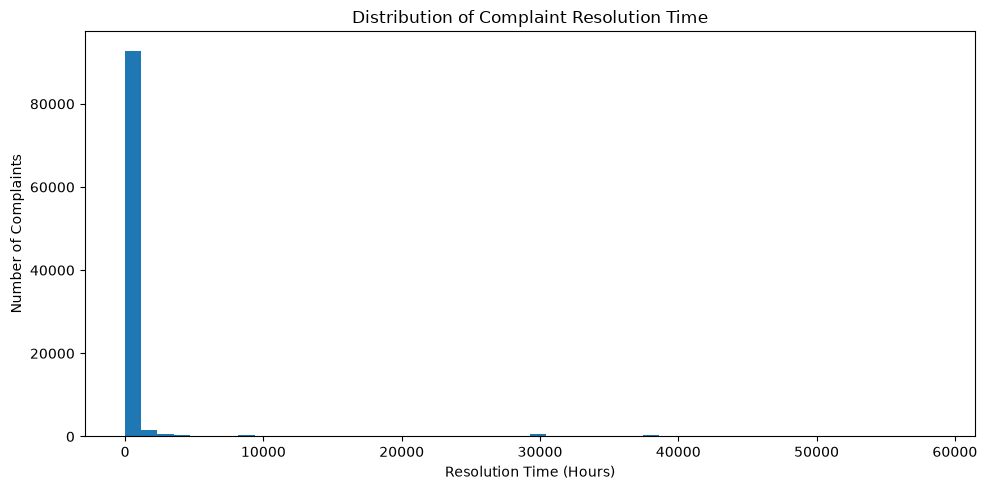

In [12]:
plt.figure(figsize=(10, 5))
plt.hist(resolution, bins=50)
plt.title("Distribution of Complaint Resolution Time")
plt.xlabel("Resolution Time (Hours)")
plt.ylabel("Number of Complaints")
plt.tight_layout()
plt.show()

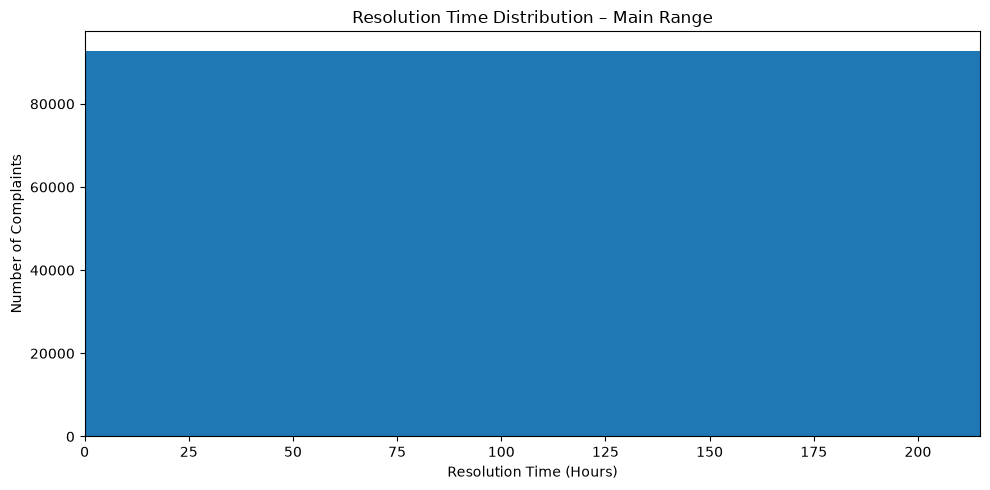

In [13]:
plt.figure(figsize=(10, 5))
plt.hist(resolution, bins=50)
plt.xlim(0, upper_limit)
plt.title("Resolution Time Distribution – Main Range")
plt.xlabel("Resolution Time (Hours)")
plt.ylabel("Number of Complaints")
plt.tight_layout()
plt.show()

C:\Users\sanka\AppData\Local\Temp\ipykernel_20560\985633359.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(resolution, vert=False)


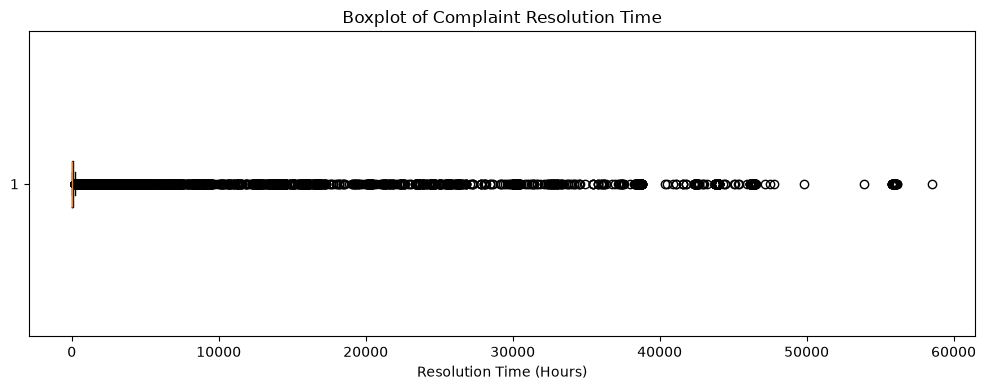

In [14]:
plt.figure(figsize=(10, 4))
plt.boxplot(resolution, vert=False)
plt.title("Boxplot of Complaint Resolution Time")
plt.xlabel("Resolution Time (Hours)")
plt.tight_layout()
plt.show()

## Statistical findings

The project analysis found a strongly right-skewed resolution-time distribution. The mean is much higher than the median because a smaller number of records have very long durations. For this reason, the median is a more representative measure of a typical resolution time.

The IQR method identifies unusually long durations. These records are retained for investigation rather than deleted automatically.